# Previsão do atraso médio de partidas com Redes Recorrentes (SimpleRNN × GRU × LSTM) com dados de voos da ANAC (VRA)

**Trabalho Prático de Deep Learning — Frente 3.2: Redes Recorrentes**

**Objetivo:** prever o **atraso médio das partidas na próxima hora** a partir do que aconteceu nas últimas 24 horas, usando três tipos de rede recorrente: **SimpleRNN, LSTM e GRU**.

**Dados:** Voo Regular Ativo (VRA) da ANAC, disponíveis em [dados.gov.br](https://dados.gov.br/dados/conjuntos-dados/dadosabertos-areas-de-atuacao-voos-e-operacoes-aereas-voo-regular-ativo-vra).

**Utilidade.** Uma estimativa do atraso médio da próxima hora ajuda o centro de operações (aeroporto, companhias, controle de tráfego) a remanejar portões, equipes de solo e tripulações antes que o atraso se propague. Também serve para avisar os passageiros com antecedência.

**Roteiro**
1. Carregar e limpar a base
2. Transformar voos individuais em uma **série temporal horária**
3. Explorar a série
4. Criar **janelas deslizantes** (o formato que uma RNN espera)
5. Dividir treino / validação / teste **respeitando o tempo**
6. Construir **baselines** simples (toda rede precisa vencê-los para valer a pena)
7. Treinar SimpleRNN, LSTM e GRU
8. Comparar e interpretar

> **Como rodar no Google Colab:** `Ambiente de execução → Executar tudo`. Se os CSVs não estiverem na pasta do notebook, a célula de carregamento baixa os arquivos diretamente da ANAC. Outra opção é enviá-los pelo ícone de pasta à esquerda.

## Por que uma rede *recorrente*?

Uma rede densa comum recebe um vetor e não sabe que a posição 1 veio antes da posição 2. Uma **RNN** lê a sequência passo a passo e carrega um **estado oculto** $h_t$ que resume o que viu até ali:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

Na prática, a SimpleRNN tem dificuldade para lembrar coisas de muitos passos atrás (o gradiente "some" ao voltar no tempo). Por isso surgiram:

- **LSTM:** adiciona uma *célula de memória* e três portas (esquecer, entrada, saída) que decidem o que guardar e o que descartar.
- **GRU:** versão simplificada, com duas portas. Costuma ter desempenho parecido com menos parâmetros.

Aqui cada passo da sequência é **uma hora**, e $x_t$ traz informações daquela hora em Guarulhos (quantos voos, atraso médio, cancelamentos, hora do dia...).

# Preparação

## Bibliotecas utizadas no projeto

In [ ]:
# ---------------------------------------------------------------------------
# Bibliotecas
# (no Colab todas já vêm instaladas; em outro ambiente, descomente a linha abaixo)
# !pip install tensorflow pandas scikit-learn matplotlib
import os
import math
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

## Constantes e Parametros

In [ ]:
SEED = 42

# 0 desativar; 1 ativar
DEBUG=1

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4)   # tamanho padrão dos gráficos
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Carregar e Limpeza de Dados

In [ ]:
# ---------------------------------------------------------------------------
# Localização dos arquivos
# O script original usava a pasta do próprio arquivo .py (__file__), que não
# existe no Colab. Aqui procuramos os CSVs em pastas comuns e, se não
# encontrarmos, baixamos direto do servidor da ANAC.
# Incluímos agora os últimos 4 meses de 2025 e os meses de 01 a 08 de 2026
# ---------------------------------------------------------------------------
MESES = [
    "VRA_2025_09.csv",
    "VRA_2025_10.csv",
    "VRA_2025_11.csv",
    "VRA_2025_12.csv",
    "VRA_2026_01.csv",
    "VRA_2026_02.csv",
    "VRA_2026_03.csv",
    "VRA_2026_04.csv",
    "VRA_2026_05.csv",
    "VRA_2026_06.csv",
    "VRA_2026_07.csv",
    "VRA_2026_08.csv"
]
PASTAS = [".", "dataset/raw", "/content", "/content/drive/MyDrive/ifg-trabalho-deep-learning/dataset/raw"]

def localizar(mes):
    """Retorna o caminho do CSV; baixa da ANAC se ele não existir localmente."""
    for pasta in PASTAS:
        caminho = os.path.join(pasta, mes)
        if os.path.exists(caminho):
            return caminho
    print(f"Baixando {mes} da ANAC...")
    # Extrai o ano do nome do arquivo para montar a URL correta
    ano = mes.split('_')[1]
    url = f"https://siros.anac.gov.br/siros/registros/diversos/vra/{ano}/{mes}"
    urllib.request.urlretrieve(url, mes)
    return mes

ARQUIVOS = [localizar(n) for n in MESES]

# Desativamos o filtro de aeroporto específico para analisar todos de forma geral
AEROPORTO = "TODOS"
#AEROPORTO = "SBGR" # SBGR é o Aeroporto de Guarulhos

# Verifica se há GPU disponível (no Colab: Ambiente de execução → Alterar tipo → GPU)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[Hardware] GPU disponível para TensorFlow: {gpus}")
else:
    print("[Hardware] TensorFlow em execução na CPU.")

# Lê todos os meses e empilha em um único DataFrame (uma linha = um voo).
# O VRA usa ';' como separador de colunas.
df = pd.concat([pd.read_csv(f, sep=";", encoding="utf-8") for f in ARQUIVOS], ignore_index=True)
print("Dados carregados com sucesso. Shape:", df.shape)

# Os nomes das colunas têm acentos ("Situação Voo", "Sigla ICAO Aeroporto Origem").
# Para não depender da codificação exata, localizamos as colunas por trechos do nome
# e as renomeamos para nomes simples.
col_situacao = [c for c in df.columns if "Situa" in c and "Voo" in c][0]
col_origem = [c for c in df.columns if "Origem" in c and "ICAO" in c][0]
df.rename(columns={col_situacao: "situacao_voo", col_origem: "origem"}, inplace=True)
display(df.head(3))

# Converte as colunas de horário (texto "dd/mm/aaaa hh:mm") para datetime.
# errors="coerce" transforma valores vazios/inválidos em NaT (data ausente).
fmt = "Format" # Not used directly if we let pandas infer, but keeping structured parsing
for col in ["Partida Prevista", "Partida Real", "Chegada Prevista", "Chegada Real"]:
    df[col] = pd.to_datetime(df[col], format="%d/%m/%Y %H:%M", errors="coerce")

print("\nSituação dos voos:")
print(df["situacao_voo"].value_counts())

[Hardware] GPU disponível para TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dados carregados com sucesso. Shape: (1018166, 21)


,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,origem,Descrição Aeroporto Origem,Partida Prevista,...,Sigla ICAO Aeroporto Destino,Descrição Aeroporto Destino,Chegada Prevista,Chegada Real,situacao_voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare
0,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,3292,6,I,E145,50,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,01/09/2025 00:00,...,SKBO,EL DORADO INTERNATIONAL AIRPORT - BOGOTÁ - COL...,01/09/2025 02:35,01/09/2025 02:29,REALIZADO,NaN,01/09/2025 00:00:00,Pontual,Antecipado,NaN
1,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,5331,9,I,E145,50,SYCJ,CHEDDI JAGAN INTERNATIONAL AIRPORT - GEORGETOW...,15/09/2025 21:00,...,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,15/09/2025 22:40,15/09/2025 22:15,REALIZADO,NaN,15/09/2025 00:00:00,Antecipado,Antecipado,NaN
2,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,Z5332,6,I,E145,0,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,NaN,...,SKBO,EL DORADO INTERNATIONAL AIRPORT - BOGOTÁ - COL...,NaN,16/09/2025 02:36,REALIZADO,NaN,15/09/2025 00:00:00,NaN,NaN,NaN



Situação dos voos:
situacao_voo
REALIZADO    988288
CANCELADO     29878
Name: count, dtype: int64


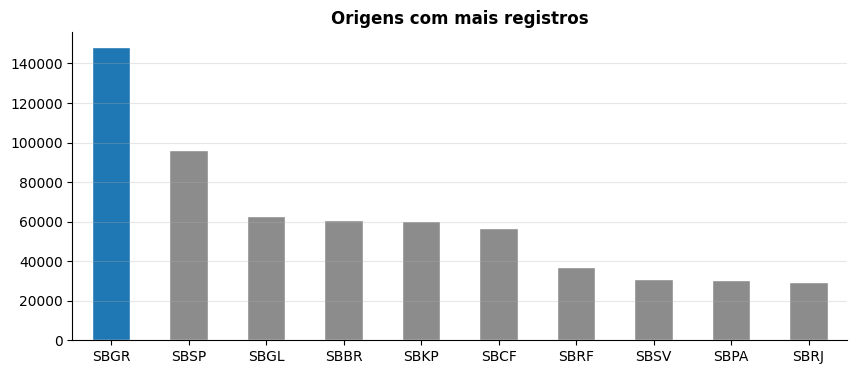

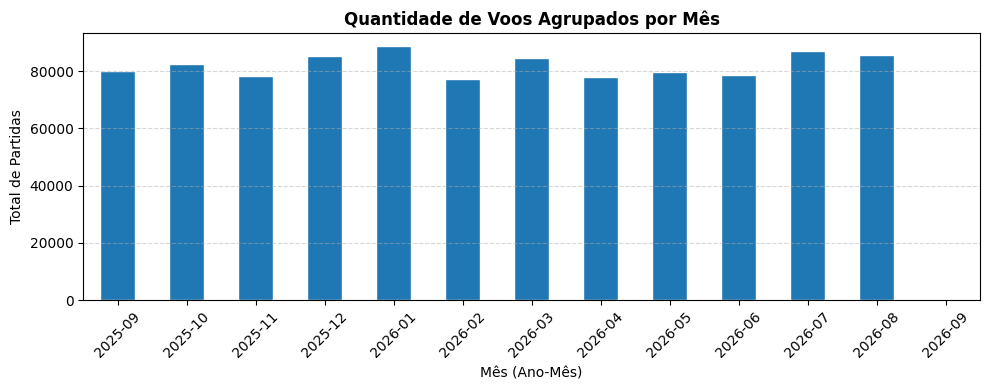

In [ ]:
# Conta os registros por origem e pega os 10 maiores
top_origens = df['origem'].value_counts().head(10)

# Define as cores: azul para SBGR, cinza para os demais
cores = ['#1f77b4' if origem == 'SBGR' else '#8c8c8c' for origem in top_origens.index]

# Cria o gráfico de barras
plt.figure(figsize=(10, 4))
top_origens.plot(kind='bar', color=cores, edgecolor='white')
plt.title('Origens com mais registros', fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='-', alpha=0.3)

# Remove as bordas superior e direita para ficar mais parecido com a imagem
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

# --- Gráfico de voos agrupados por mês ---
# Extrai o ano e o mês no formato YYYY-MM para ordenação e agrupamento correto
p_temp = df.copy()
p_temp['ano_mes'] = p_temp['Partida Prevista'].dt.to_period('M')
voos_por_mes = p_temp.groupby('ano_mes').size()

plt.figure(figsize=(10, 4))
voos_por_mes.plot(kind='bar', color='tab:blue', edgecolor='white')
plt.title('Quantidade de Voos Agrupados por Mês', fontweight='bold')
plt.xlabel('Mês (Ano-Mês)')
plt.ylabel('Total de Partidas')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Mantém todos os voos de partida de qualquer origem (não filtra por aeroporto específico)
p = df.copy()

# Sem horário previsto não dá para posicionar o voo no tempo -> descarta
p = p.dropna(subset=["Partida Prevista"])

# Atraso de partida em minutos (negativo = saiu antes do previsto).
# Para cancelados o resultado é NaN, pois não há partida real.
p["atraso_min"] = (p["Partida Real"] - p["Partida Prevista"]).dt.total_seconds() / 60

# Limita (clip) valores extremos: abaixo de -60 vira -60, acima de 300 vira 300
p["atraso_min"] = p["atraso_min"].clip(-60, 300)

# Indicador 0/1 de cancelamento
p["cancelado"] = (p["situacao_voo"] == "CANCELADO").astype(int)

display(p.head())

print(f"{len(p):,} partidas previstas no total (Brasil) | canceladas: {p['cancelado'].sum():,}")
print("\nEstatísticas descritivas do atraso geral (min):")
print(p["atraso_min"].describe().round(1))

,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,origem,Descrição Aeroporto Origem,Partida Prevista,...,Chegada Prevista,Chegada Real,situacao_voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare,atraso_min,cancelado
0,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,3292,6,I,E145,50,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,2025-09-01 00:00:00,...,2025-09-01 02:35:00,2025-09-01 02:29:00,REALIZADO,NaN,01/09/2025 00:00:00,Pontual,Antecipado,NaN,3.0,0
1,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,5331,9,I,E145,50,SYCJ,CHEDDI JAGAN INTERNATIONAL AIRPORT - GEORGETOW...,2025-09-15 21:00:00,...,2025-09-15 22:40:00,2025-09-15 22:15:00,REALIZADO,NaN,15/09/2025 00:00:00,Antecipado,Antecipado,NaN,-33.0,0
3,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,5332,2,I,E145,50,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,2025-09-16 00:00:00,...,2025-09-16 02:35:00,NaT,CANCELADO,NaN,16/09/2025 00:00:00,NaN,NaN,NaN,NaN,1
4,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,5331,9,I,E145,50,SYCJ,CHEDDI JAGAN INTERNATIONAL AIRPORT - GEORGETOW...,2025-09-30 21:00:00,...,2025-09-30 22:40:00,2025-09-30 22:38:00,REALIZADO,NaN,30/09/2025 00:00:00,Antecipado,Antecipado,NaN,-28.0,0
5,AAL,"AMERICAN AIRLINES, INC.",0904,0,I,B772,288,SBGL,AEROPORTO INTERNACIONAL DO RIO DE JANEIRO (GAL...,2025-09-01 23:00:00,...,2025-09-02 07:40:00,2025-09-02 07:22:00,REALIZADO,NaN,01/09/2025 00:00:00,Antecipado,Antecipado,NaN,-8.0,0


986,807 partidas previstas no total (Brasil) | canceladas: 29,878

Estatísticas descritivas do atraso geral (min):
count    956929.0
mean          7.0
std          31.9
min         -60.0
25%          -7.0
50%          -1.0
75%           9.0
max         300.0
Name: atraso_min, dtype: float64


O atraso de partida é `Partida Real − Partida Prevista`, em minutos.

Dois cuidados:
- Voos **cancelados** não têm horário real. Eles entram como *contagem de cancelamentos*, não como atraso.
- Há valores extremos (atrasos de dias, ou registros com partida muito antes do previsto). O atraso é limitado a **[-60, 300] min** para que poucos casos estranhos não dominem a média da hora.

# 2. De voos para série temporal horária

Cada linha do VRA é um voo. A RNN precisa de uma **sequência regular no tempo**, então os dados são agregados por hora (pelo horário *previsto* de partida):

| feature | significado |
|---|---|
| `n_voos` | partidas previstas na hora |
| `atraso_medio` | atraso médio dos voos realizados (**é o que queremos prever**) |
| `pct_atrasados` | fração com mais de 15 min de atraso |
| `n_cancel` | voos cancelados |
| `hora_sin`, `hora_cos` | hora do dia em forma circular (23h fica perto de 0h) |
| `fim_semana` | sábado ou domingo |

Horas sem nenhum voo realizado ficam com atraso 0 e são sinalizadas por `n_voos`.

In [ ]:
# "Arredonda" o horário previsto para baixo, até a hora cheia (ex.: 14:37 -> 14:00).
# Essa será a chave de agrupamento.
p["hora"] = p["Partida Prevista"].dt.floor("h")

# Para estatísticas de atraso usamos só voos realizados (cancelados não têm atraso)
realizados = p[p["cancelado"] == 0]

# Cada coluna é uma agregação por hora; o pandas alinha tudo pelo índice "hora"
serie = pd.DataFrame({
    "n_voos": p.groupby("hora").size(),                                   # total de partidas previstas
    "atraso_medio": realizados.groupby("hora")["atraso_min"].mean(),       # ALVO
    "pct_atrasados": realizados.groupby("hora")["atraso_min"].apply(lambda s: (s > 15).mean()),
    "n_cancel": p.groupby("hora")["cancelado"].sum(),
})

# Grade horária completa (set/01 00h a ago/31 23h): horas sem nenhum voo não
# aparecem no groupby, então reindexamos e preenchemos as lacunas com 0.
inicio, fim = pd.Timestamp("2025-09-01 00:00"), pd.Timestamp("2026-08-31 23:00")
serie = serie.reindex(pd.date_range(inicio, fim, freq="h")).fillna(0)

# Codificação cíclica da hora: seno e cosseno colocam 23h e 0h lado a lado,
# o que não aconteceria usando a hora como número de 0 a 23.
h = serie.index.hour
serie["hora_sin"] = np.sin(2 * np.pi * h / 24)
serie["hora_cos"] = np.cos(2 * np.pi * h / 24)

# 1 para sábado/domingo (dayofweek 5 e 6), 0 para dias úteis
serie["fim_semana"] = (serie.index.dayofweek >= 5).astype(int)

print(serie.shape)   # (horas, colunas)
serie.head(24)

(8760, 7)


,n_voos,atraso_medio,pct_atrasados,n_cancel,hora_sin,hora_cos,fim_semana
2025-09-01 00:00:00,19,20.052632,0.210526,0,0.000000e+00,1.000000e+00,0
2025-09-01 01:00:00,26,1.260870,0.043478,3,2.588190e-01,9.659258e-01,0
2025-09-01 02:00:00,52,1.884615,0.115385,0,5.000000e-01,8.660254e-01,0
2025-09-01 03:00:00,48,-5.437500,0.020833,0,7.071068e-01,7.071068e-01,0
2025-09-01 04:00:00,49,-2.791667,0.062500,1,8.660254e-01,5.000000e-01,0
2025-09-01 05:00:00,92,-4.641304,0.054348,0,9.659258e-01,2.588190e-01,0
2025-09-01 06:00:00,124,3.247934,0.082645,3,1.000000e+00,6.123234e-17,0
2025-09-01 07:00:00,104,7.718447,0.067961,1,9.659258e-01,-2.588190e-01,0
2025-09-01 08:00:00,176,4.976879,0.109827,3,8.660254e-01,-5.000000e-01,0
2025-09-01 09:00:00,160,0.602564,0.070513,4,7.071068e-01,-7.071068e-01,0


# 3. Explorando a série

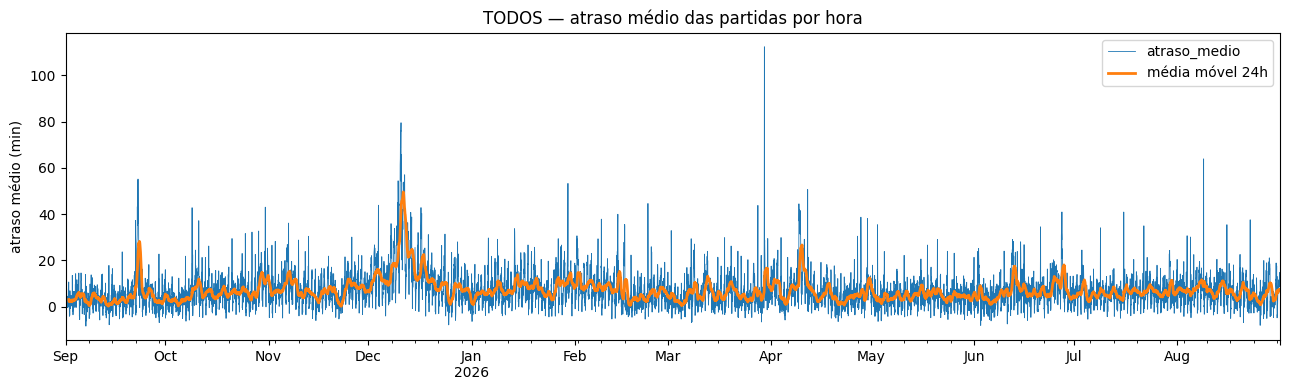

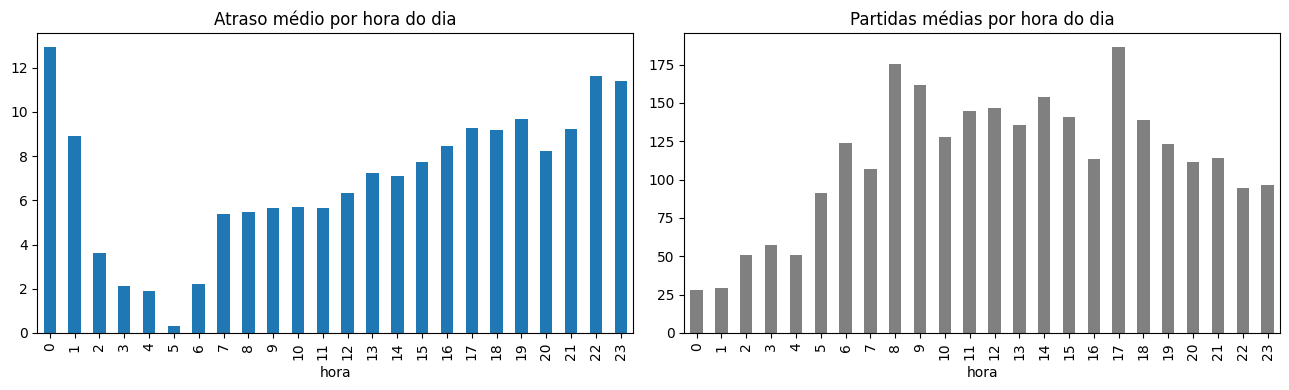

In [ ]:
# Pasta onde os gráficos também serão salvos em PNG (além de exibidos na tela)
os.makedirs("figuras", exist_ok=True)

# Gráfico 1: apenas o atraso médio hora a hora (linha fina) + média móvel de 24 h (linha grossa)
fig, ax = plt.subplots(figsize=(13, 4))
serie["atraso_medio"].plot(ax=ax, lw=0.6)
serie["atraso_medio"].rolling(24).mean().plot(ax=ax, lw=2, label="média móvel 24h")
ax.set_ylabel("atraso médio (min)")
ax.legend()
ax.set_title(f"{AEROPORTO} — atraso médio das partidas por hora")
plt.tight_layout()
plt.savefig("figuras/01_serie_temporal.png", dpi=150)
plt.show()

# Gráfico 2: perfil médio por hora do dia (ciclo diário)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
serie.groupby(serie.index.hour)["atraso_medio"].mean().plot.bar(ax=ax[0], color="tab:blue")
ax[0].set_title("Atraso médio por hora do dia"); ax[0].set_xlabel("hora")
serie.groupby(serie.index.hour)["n_voos"].mean().plot.bar(ax=ax[1], color="gray")
ax[1].set_title("Partidas médias por hora do dia"); ax[1].set_xlabel("hora")
plt.tight_layout()
plt.savefig("figuras/02_atraso_por_hora.png", dpi=150)
plt.show()

Repare em dois padrões que a RNN pode aprender: o **ciclo diário** (o atraso cresce ao longo do dia, quando atrasos anteriores se propagam) e a **persistência** (uma hora ruim costuma ser seguida de outra ruim). A madrugada tem poucos voos, então a média ali é mais ruidosa.

O `EarlyStopping` interrompe o treino quando o erro na validação para de melhorar e volta aos melhores pesos. A perda é **Huber**, menos sensível a horas com atraso extremo do que o erro quadrático.

## Janelas deslizantes

Uma RNN no Keras recebe um tensor 3D: **(amostras, passos no tempo, features)**.

Com `JANELA = 24`, cada amostra é: *as 24 horas anteriores (todas as features)* → *o atraso médio da hora seguinte*.

```
horas  t-24 ... t-2  t-1  |  t
       [------- X -------]  -> y
```

## Divisão temporal (treino / validação / teste)

Em série temporal **nunca** se embaralha antes de dividir, porque isso deixaria o modelo "ver o futuro". A divisão usada é:

- **treino:** 60% do dataset
- **validação:** 20% do dataset (para escolher quando parar o treino)
- **teste:** 20% do dataset (só olhamos no final)

O `StandardScaler` é ajustado **só no treino** e depois aplicado aos outros conjuntos.

# 4. Treinando as Redes Neurais Recorrentes

Execução multi-janelas (24h, 48h, 168h)
Abaixo criaremos uma rotina para automatizar o treinamento e avaliação das três arquiteturas para cada uma das larguras de janela solicitadas.

In [ ]:
FEATURES = ["atraso_medio", "n_voos", "pct_atrasados", "n_cancel", "hora_sin", "hora_cos", "fim_semana"]
ALVO = "atraso_medio"         # variável que a rede vai prever
JANELAS_TESTAR = [24, 48, 168]     # quantas horas passadas a rede enxerga

# Dicionário para armazenar as métricas de teste obtidas
resultados_multi_janelas = []

# Dicionários para guardar os modelos e históricos já treinados e evitar re-treinamento depois
modelos_treinados = {}
historicos_treinados = {}

# Últimas horas de treino e de validação (60% treino, 20% validação, 20% teste)
n_horas = len(serie)
fim_treino = serie.index[int(n_horas * 0.6) - 1]
fim_val = serie.index[int(n_horas * 0.8) - 1]

# Padronização: média e desvio calculados SÓ com o período de treino (.loc[:fim_treino])
# e depois aplicados à série inteira. Assim nenhuma estatística do futuro vaza para o treino.
scaler_x = StandardScaler().fit(serie.loc[:fim_treino, FEATURES])    # para as entradas
scaler_y = StandardScaler().fit(serie.loc[:fim_treino, [ALVO]])      # para o alvo (permite desfazer depois)
X_all = scaler_x.transform(serie[FEATURES])
y_all = scaler_y.transform(serie[[ALVO]]).ravel()

def criar_janelas_local(X, y, janela):
    Xs, ys, idx = [], [], []
    for t in range(janela, len(X)):
        Xs.append(X[t - janela:t])     # horas t-janela ... t-1 (todas as features)
        ys.append(y[t])                # hora t (a "próxima")
        idx.append(serie.index[t])     # guarda a data/hora do alvo para dividir por período
    return np.array(Xs), np.array(ys), pd.DatetimeIndex(idx)

for janela in JANELAS_TESTAR:
    print(f"\n{'='*50}\nPROCESSANDO JANELA TEMPORAL DE {janela} HORAS\n{'='*50}")

    # Recria os conjuntos de dados para esta janela específica
    X, y, tempo = criar_janelas_local(X_all, y_all, janela)

    # Separação Temporal
    tr, va, te = tempo <= fim_treino, (tempo > fim_treino) & (tempo <= fim_val), tempo > fim_val
    X_tr, y_tr = X[tr], y[tr]
    X_va, y_va = X[va], y[va]
    X_te, y_te = X[te], y[te]

    y_real_te = serie.loc[tempo[te], ALVO].values

    for tipo in ["SimpleRNN", "LSTM", "GRU"]:
        print(f"\nTreinando modelo {tipo} com janela {janela}...")
        tf.random.set_seed(SEED)

        # Reconstrói o modelo com a largura da janela atual
        camada = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]

        opt = keras.optimizers.Adam(learning_rate=0.003)
        modelo = keras.Sequential()

        modelo.add(layers.Input(shape=(janela, len(FEATURES))))

        # Correção: a primeira camada recorrente deve retornar sequências se houver outra depois
        modelo.add(camada(16, activation='tanh', kernel_initializer='random_uniform', return_sequences=True, use_bias=True))
        modelo.add(layers.Dropout(0.2))

        # A última camada recorrente antes da camada Dense não precisa retornar sequências (False)
        modelo.add(camada(16, activation='tanh', kernel_initializer='random_uniform', return_sequences=False, use_bias=True))
        modelo.add(layers.Dropout(0.2))

        modelo.add(layers.Dense(1, activation='linear', use_bias=True))
        modelo.compile(loss='mean_squared_error', optimizer=opt, metrics=["mae"])
        modelo.summary()

        momento_parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

        hist = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=100, batch_size=32, callbacks=[momento_parar], verbose=DEBUG)

        # Salva o modelo e o histórico de treinamento na memória para reutilização posterior
        modelos_treinados[(janela, tipo)] = modelo
        historicos_treinados[(janela, tipo)] = hist.history

        # Previsão e despadronização
        prev_padronizada = modelo.predict(X_te, verbose=DEBUG).ravel()
        prev_minutos = scaler_y.inverse_transform(prev_padronizada.reshape(-1, 1)).ravel()

        # Avaliação de métricas
        mae_teste = np.mean(np.abs(y_real_te - prev_minutos))
        rmse_teste = math.sqrt(mean_squared_error(y_real_te, prev_minutos))

        resultados_multi_janelas.append({
            "Janela (horas)": janela,
            "Modelo": tipo,
            "MAE Teste (min)": mae_teste,
            "RMSE Teste (min)": rmse_teste
        })
        print(f"Resultado [{tipo} - Janela {janela}]: MAE = {mae_teste:.2f} min, RMSE = {rmse_teste:.2f} min")



PROCESSANDO JANELA TEMPORAL DE 24 HORAS

Treinando modelo SimpleRNN com janela 24...


Model: "sequential_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_27 (SimpleRNN)       │ (None, 24, 16)         │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_81 (Dropout)            │ (None, 24, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_28 (SimpleRNN)       │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_82 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_27 (GRU)                    │ (None, 168, 16)        │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_97 (Dropout)            │ (None, 168, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_28 (GRU)                    │ (None, 16)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_98 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,849 (11.13 KB)

 Trainable params: 2,849 (11.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4834 - mae: 0.4786 - val_loss: 0.3355 - val_mae: 0.4071
Epoch 2/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3993 - mae: 0.4406 - val_loss: 0.3244 - val_mae: 0.3987
Epoch 3/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3787 - mae: 0.4298 - val_loss: 0.3156 - val_mae: 0.3914
Epoch 4/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.3621 - mae: 0.4235 - val_loss: 0.3101 - val_mae: 0.3848
Epoch 5/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3547 - mae: 0.4166 - val_loss: 0.3129 - val_mae: 0.3845
Epoch 6/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3483 - mae: 0.4128 - val_loss: 0.3088 - val_mae: 0.3850
Epoch 7/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3430 - mae: 0.4122 - val_loss: 0.3134 - val_mae: 0.3890
Epoch 8/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3386 - mae: 0.4116 - val_loss: 0.3138 - val_mae: 0.3870
Epoch 9/100
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms

## Gráficos e Resultados

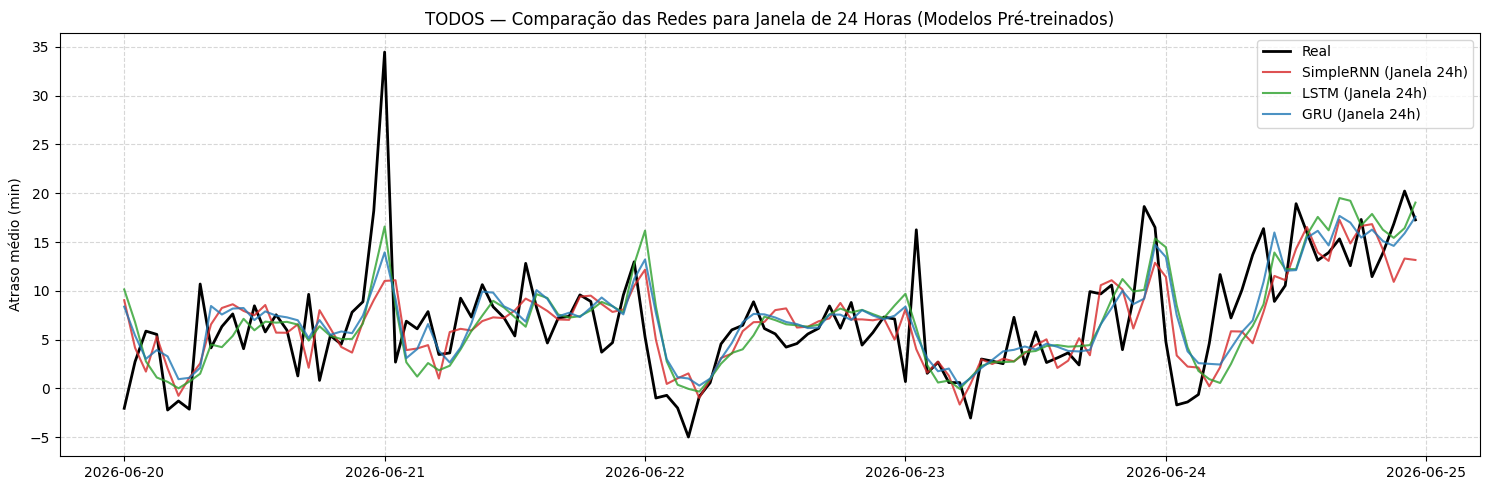

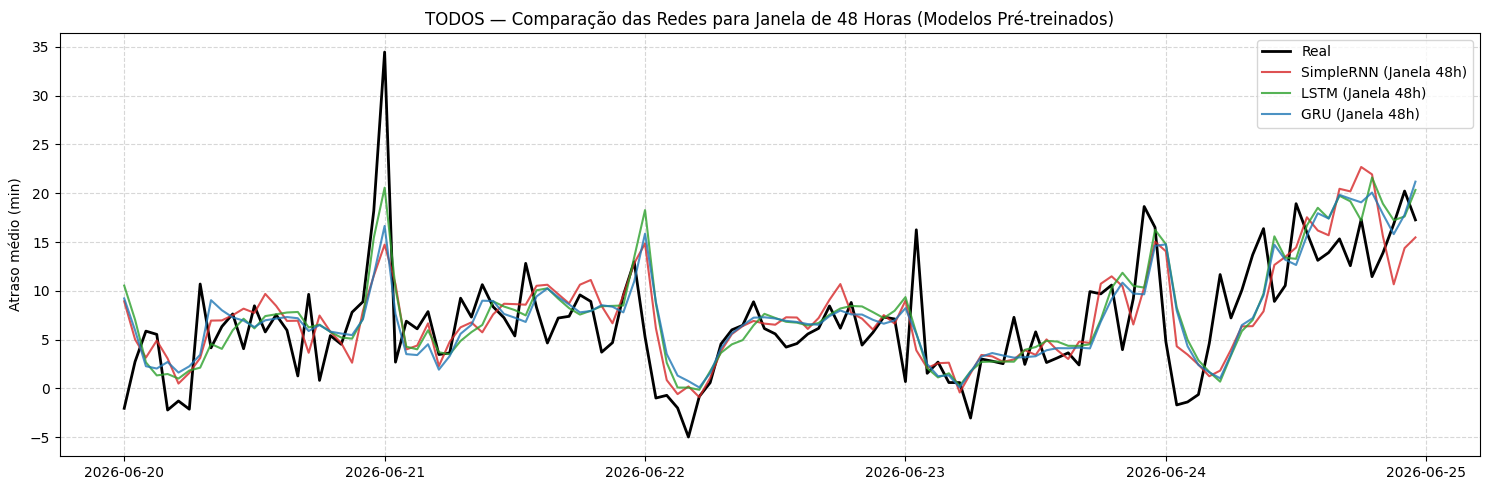

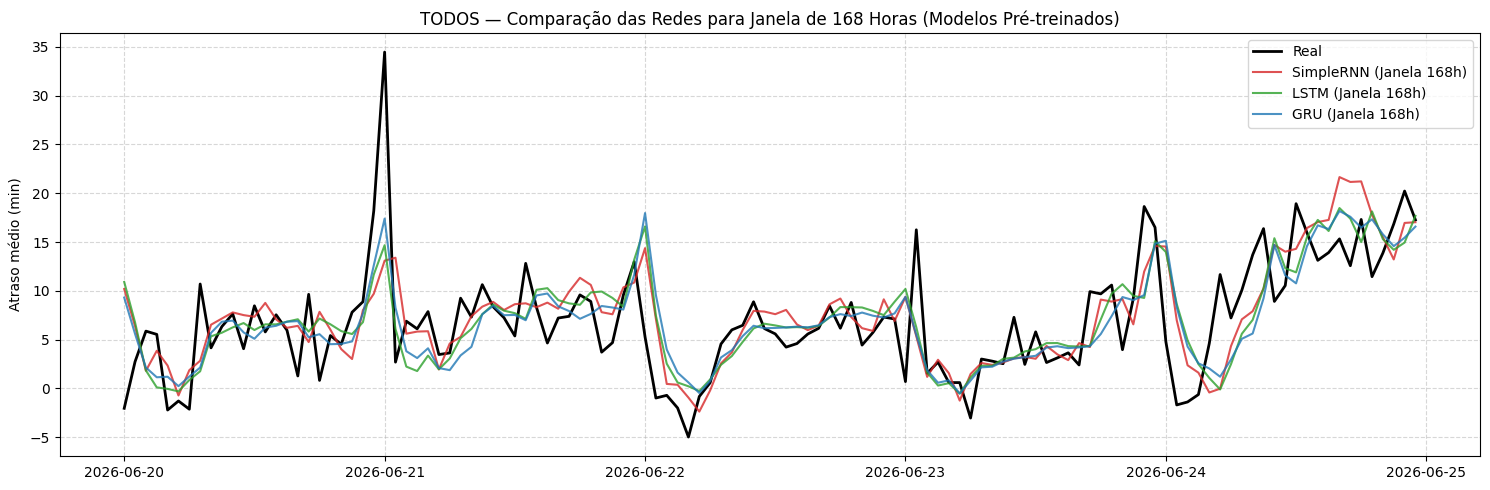

In [ ]:
# ---------------------------------------------------------------------------
# Geração de gráficos utilizando os modelos JÁ TREINADOS e armazenados na memória
# ---------------------------------------------------------------------------
janela_plot = slice(0, 24 * 5)  # Primeiros 5 dias do período de teste
cores = {"SimpleRNN": "tab:red", "LSTM": "tab:green", "GRU": "tab:blue"}

# Agrupando os dados de previsões detalhadas por janela no loop
for janela in JANELAS_TESTAR:
    plt.figure(figsize=(15, 5))

    # Recria os conjuntos de tempo e o real correspondentes a esta janela específica
    _, _, tempo_local = criar_janelas_local(X_all, y_all, janela)
    te_local = tempo_local > fim_val
    idx_te_local = tempo_local[te_local]
    y_real_te_local = serie.loc[idx_te_local, ALVO].values

    # Plota a série real
    plt.plot(idx_te_local[janela_plot], y_real_te_local[janela_plot], label="Real", color="black", lw=2)

    # Filtra e plota as previsões desta janela para cada rede
    for tipo in ["SimpleRNN", "LSTM", "GRU"]:
        # Recupera diretamente o modelo já treinado que guardamos no dicionário
        modelo_local = modelos_treinados.get((janela, tipo))

        if modelo_local is not None:
            # Separamos os dados específicos desta janela para predição
            X_local, _, _ = criar_janelas_local(X_all, y_all, janela)
            X_te_local = X_local[te_local]

            # Realiza a predição diretamente, sem necessidade de re-treinamento
            prev_padronizada = modelo_local.predict(X_te_local, verbose=0).ravel()
            prev_minutos = scaler_y.inverse_transform(prev_padronizada.reshape(-1, 1)).ravel()

            plt.plot(idx_te_local[janela_plot], prev_minutos[janela_plot], label=f"{tipo} (Janela {janela}h)", color=cores[tipo], lw=1.5, alpha=0.8)
        else:
            print(f"Aviso: O modelo treinado para Janela {janela}h e tipo {tipo} não foi encontrado.")

    plt.ylabel("Atraso médio (min)")
    plt.title(f"{AEROPORTO} — Comparação das Redes para Janela de {janela} Horas (Modelos Pré-treinados)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"figuras/comparativo_janela_{janela}.png", dpi=150)
    plt.show()

In [ ]:
# Apresentação consolidada de todas as execuções
df_resultados = pd.DataFrame(resultados_multi_janelas)
display(df_resultados.sort_values(by="MAE Teste (min)"))

,Janela (horas),Modelo,MAE Teste (min),RMSE Teste (min)
8,168,GRU,3.071304,4.561301
7,168,LSTM,3.099718,4.622849
2,24,GRU,3.107078,4.572445
5,48,GRU,3.137371,4.653310
1,24,LSTM,3.138667,4.674804
6,168,SimpleRNN,3.194278,4.724112
0,24,SimpleRNN,3.219827,4.725091
4,48,LSTM,3.233528,4.824697
3,48,SimpleRNN,3.285960,4.785775


### Curvas de Aprendizado (Loss) para cada Janela e Modelo
O código abaixo realiza o treinamento das arquiteturas (SimpleRNN, LSTM, GRU) para cada uma das janelas (24h, 48h, 168h) e exibe as curvas de perda de treino e validação lado a lado em uma grade organizada.

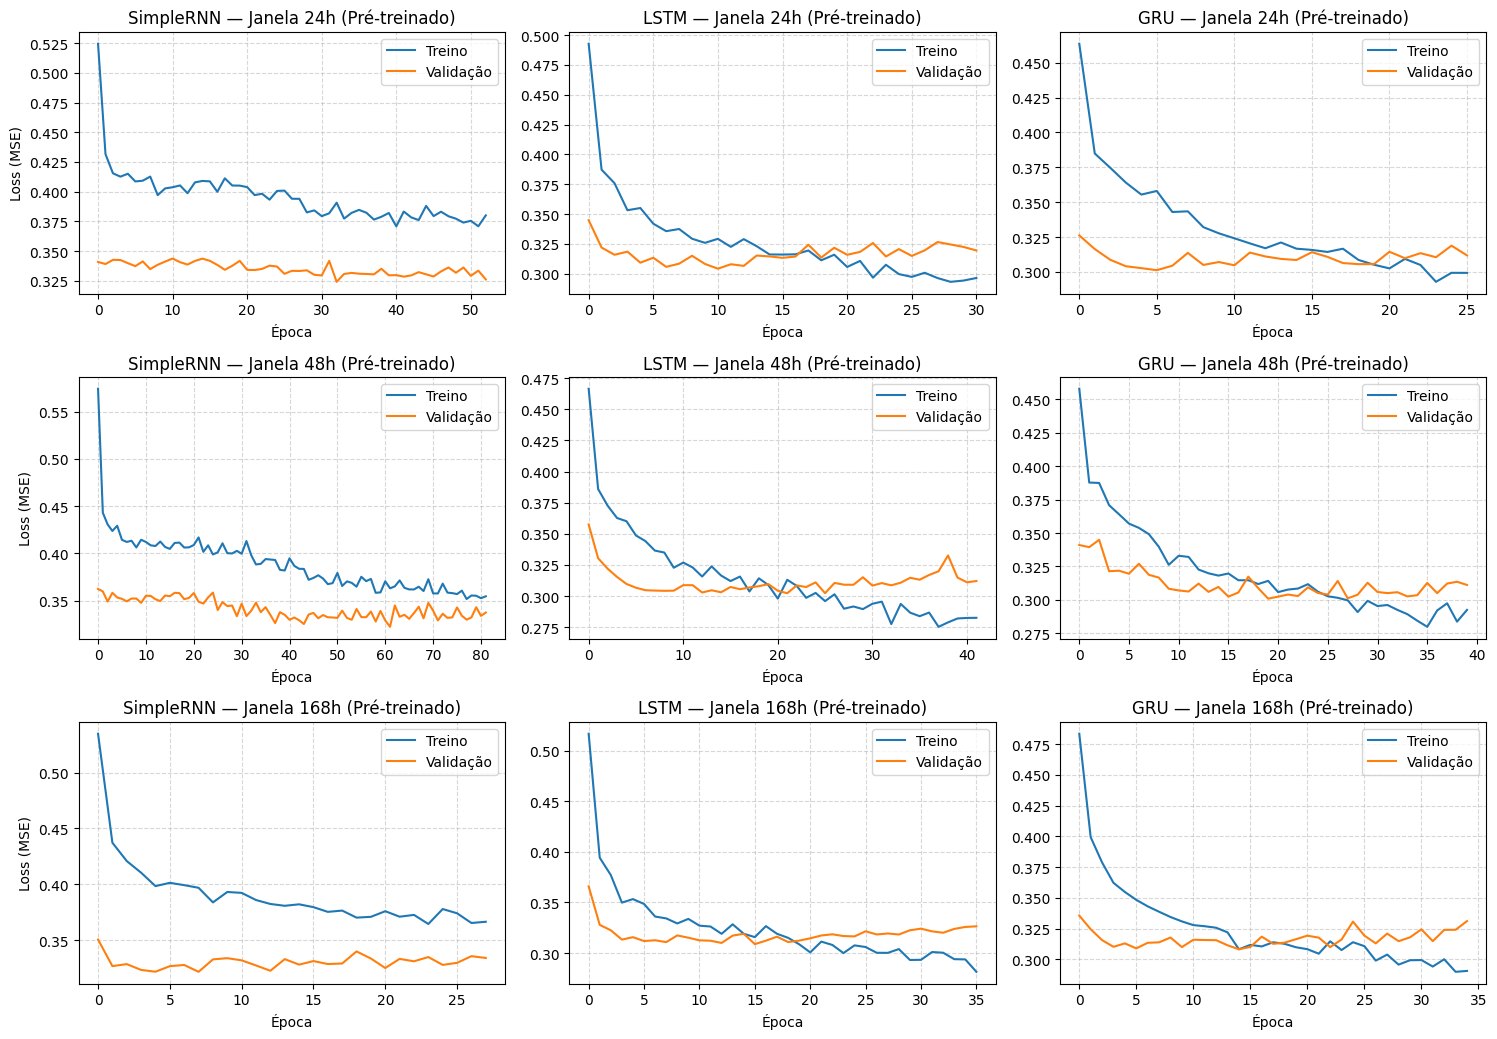

In [ ]:
# ---------------------------------------------------------------------------
# Geração das curvas de Loss utilizando o histórico de treino já salvo em memória
# ---------------------------------------------------------------------------
import matplotlib.pyplot as plt

# Usamos squeeze=False para garantir que axs sempre seja uma matriz 2D, mesmo se houver apenas 1 janela
fig, axs = plt.subplots(len(JANELAS_TESTAR), 3, figsize=(15, 3.5 * len(JANELAS_TESTAR)), sharey=False, squeeze=False)

for idx_j, janela in enumerate(JANELAS_TESTAR):
    for idx_t, tipo in enumerate(["SimpleRNN", "LSTM", "GRU"]):
        # Recupera diretamente o histórico salvo
        historico = historicos_treinados.get((janela, tipo))

        ax = axs[idx_j, idx_t]
        if historico is not None:
            ax.plot(historico["loss"], label="Treino", color="tab:blue")
            ax.plot(historico["val_loss"], label="Validação", color="tab:orange")
            ax.set_title(f"{tipo} — Janela {janela}h (Pré-treinado)")
            ax.set_xlabel("Época")
            if idx_t == 0:
                ax.set_ylabel("Loss (MSE)")
            ax.legend()
            ax.grid(True, linestyle="--", alpha=0.5)
        else:
            ax.text(0.5, 0.5, f"Histórico não encontrado\n({tipo} - {janela}h)",
                    horizontalalignment='center', verticalalignment='center')

plt.tight_layout()
plt.savefig("figuras/curvas_aprendizado_multi_janelas.png", dpi=150)
plt.show()

# 5. Otimização de Hiperparâmetros com Optuna

Vamos utilizar a biblioteca **Optuna** para encontrar a melhor combinação de hiperparâmetros para a nossa rede recorrente. Vamos otimizar:
- O número de unidades da camada recorrente (GRU/LSTM)
- A taxa de dropout
- A taxa de aprendizado (learning rate)


In [ ]:
# Instala o Optuna de forma silenciosa
!pip install optuna -q

In [ ]:
import optuna
import logging

# Desativa logs excessivos do Optuna para manter a saída limpa
optuna.logging.set_verbosity(optuna.logging.WARNING)

janela_opt = 24
X_opt, y_opt, tempo_opt = criar_janelas_local(X_all, y_all, janela_opt)

tr_opt = tempo_opt <= fim_treino
va_opt = (tempo_opt > fim_treino) & (tempo_opt <= fim_val)
X_tr_opt, y_tr_opt = X_opt[tr_opt], y_opt[tr_opt]
X_va_opt, y_va_opt = X_opt[va_opt], y_opt[va_opt]

def objective(trial):
    # Hiperparâmetros a serem otimizados
    unidades = trial.suggest_int("unidades", 16, 64, step=16)
    dropout_rate = trial.suggest_float("dropout_rate", 0.0, 0.5, step=0.1)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    tipo_rede = trial.suggest_categorical("tipo_rede", ["SimpleRNN", "LSTM", "GRU"])
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    # Construção do modelo dinâmico
    camada = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo_rede]

    modelo = keras.Sequential()
    modelo.add(layers.Input(shape=(janela_opt, len(FEATURES))))
    modelo.add(camada(unidades, activation='tanh', return_sequences=False, use_bias=True))
    modelo.add(layers.Dropout(dropout_rate))
    modelo.add(layers.Dense(1, activation='linear', use_bias=True))

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="mean_squared_error",
        metrics=["mae"]
    )

    momento_parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

    # Treinamento rápido para validação dos parâmetros utilizando o batch_size sugerido
    modelo.fit(
        X_tr_opt, y_tr_opt,
        validation_data=(X_va_opt, y_va_opt),
        epochs=15,
        batch_size=batch_size,
        callbacks=[momento_parar],
        verbose=DEBUG
    )
    #modelo.summary()

    # evaluate retorna uma lista: [loss, mae]. Pegamos apenas o índice 0 (loss) para o Optuna.
    metrics_eval = modelo.evaluate(X_va_opt, y_va_opt, verbose=0)
    val_loss = metrics_eval[0] if isinstance(metrics_eval, list) else metrics_eval
    return val_loss

# Criando e executando o estudo do Optuna
study = optuna.create_study(direction="minimize")
print("Iniciando a busca de hiperparâmetros com o Optuna (5 trials)... ")
study.optimize(objective, n_trials=5)

print("\nMelhores Hiperparâmetros Encontrados:")
for chave, valor in study.best_params.items():
    print(f"  - {chave}: {valor}")
print(f"  - Melhor Loss de Validação: {study.best_value:.4f}")

Iniciando a busca de hiperparâmetros com o Optuna (5 trials)... 
Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.1042 - mae: 0.7298 - val_loss: 0.5615 - val_mae: 0.5515
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7115 - mae: 0.5726 - val_loss: 0.4353 - val_mae: 0.4875
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5676 - mae: 0.5160 - val_loss: 0.3905 - val_mae: 0.4606
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5143 - mae: 0.4935 - val_loss: 0.3694 - val_mae: 0.4434
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4744 - mae: 0.4799 - val_loss: 0.3605 - val_mae: 0.4353
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4620 - mae: 0.4737 - val_loss: 0.3542 - val_mae: 0.4306
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4517 - mae: 0.4680 - val_loss: 0.3493 - val_mae: 0.4263
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4299 - mae: 0.4588 - val_loss: 0.3452 - val_mae: 0.4230
Epoch 9

# 6. Treinando as Redes Neurais Recorrentes com Otimização de Hiperparâmetros com Optuna

Execução multi-janelas (24h, 48h, 168h)
Abaixo criaremos uma rotina para automatizar o treinamento e avaliação das três arquiteturas para cada uma das larguras de janela solicitadas.

In [ ]:
#Melhores Hiperparâmetros Encontrados:
#  - unidades: 48
#  - dropout_rate: 0.4
#  - lr: 0.001353557296421454
#  - tipo_rede: LSTM
#  - batch_size: 16
#  - Melhor Loss de Validação: 0.2990
OPTUNA_UNIDADES = 48
OPTUNA_DROPOUT_RATE = 0.4
OPTUNA_LR = 0.001353557296421454
OPTUNA_BATCH_SIZE = 16

FEATURES = ["atraso_medio", "n_voos", "pct_atrasados", "n_cancel", "hora_sin", "hora_cos", "fim_semana"]
ALVO = "atraso_medio"              # variável que a rede vai prever
JANELAS_TESTAR_OPTUNA = [24]     # quantas horas passadas a rede enxerga

# Dicionário para armazenar as métricas de teste obtidas
resultados_multi_janelas = []

# Dicionários para guardar os modelos e históricos já treinados e evitar re-treinamento depois
modelos_treinados = {}
historicos_treinados = {}

# Últimas horas de treino e de validação (60% treino, 20% validação, 20% teste)
n_horas = len(serie)
fim_treino = serie.index[int(n_horas * 0.6) - 1]
fim_val = serie.index[int(n_horas * 0.8) - 1]

# Padronização: média e desvio calculados SÓ com o período de treino (.loc[:fim_treino])
# e depois aplicados à série inteira. Assim nenhuma estatística do futuro vaza para o treino.
scaler_x = StandardScaler().fit(serie.loc[:fim_treino, FEATURES])    # para as entradas
scaler_y = StandardScaler().fit(serie.loc[:fim_treino, [ALVO]])      # para o alvo (permite desfazer depois)
X_all = scaler_x.transform(serie[FEATURES])
y_all = scaler_y.transform(serie[[ALVO]]).ravel()

def criar_janelas_local(X, y, janela):
    Xs, ys, idx = [], [], []
    for t in range(janela, len(X)):
        Xs.append(X[t - janela:t])     # horas t-janela ... t-1 (todas as features)
        ys.append(y[t])                # hora t (a "próxima")
        idx.append(serie.index[t])     # guarda a data/hora do alvo para dividir por período
    return np.array(Xs), np.array(ys), pd.DatetimeIndex(idx)

for janela in JANELAS_TESTAR_OPTUNA:
    print(f"\n{'='*50}\nPROCESSANDO JANELA TEMPORAL DE {janela} HORAS\n{'='*50}")

    # Recria os conjuntos de dados para esta janela específica
    X, y, tempo = criar_janelas_local(X_all, y_all, janela)

    # Separação Temporal
    tr, va, te = tempo <= fim_treino, (tempo > fim_treino) & (tempo <= fim_val), tempo > fim_val
    X_tr, y_tr = X[tr], y[tr]
    X_va, y_va = X[va], y[va]
    X_te, y_te = X[te], y[te]

    y_real_te = serie.loc[tempo[te], ALVO].values

    for tipo in ["SimpleRNN", "LSTM", "GRU"]:
        print(f"\nTreinando modelo {tipo} com janela {janela}...")
        tf.random.set_seed(SEED)

        # Reconstrói o modelo com a largura da janela atual
        camada = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]

        opt = keras.optimizers.Adam(learning_rate=OPTUNA_LR)
        modelo = keras.Sequential()
        modelo.add(layers.Input(shape=(janela, len(FEATURES))))

        # Correção: a primeira camada recorrente deve retornar sequências se houver outra depois
        modelo.add(camada(OPTUNA_UNIDADES, activation='tanh', kernel_initializer='random_uniform', return_sequences=True, use_bias=True))
        modelo.add(layers.Dropout(OPTUNA_DROPOUT_RATE))

        # A segunda e última camada recorrente antes da camada Densa NÃO deve retornar sequências
        modelo.add(camada(OPTUNA_UNIDADES, activation='tanh', kernel_initializer='random_uniform', return_sequences=False, use_bias=True))
        modelo.add(layers.Dropout(OPTUNA_DROPOUT_RATE))

        modelo.add(layers.Dense(1, activation='linear', use_bias=True))
        # optimizer='RMSProp'
        modelo.compile(loss='mean_squared_error', optimizer=opt, metrics=["mae"])
        modelo.summary()

        momento_parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

        hist = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=100, batch_size=OPTUNA_BATCH_SIZE, callbacks=[momento_parar], verbose=DEBUG)

        # Salva o modelo e o histórico de treinamento na memória para reutilização posterior
        modelos_treinados[(janela, tipo)] = modelo
        historicos_treinados[(janela, tipo)] = hist.history

        # Previsão e despadronização
        prev_padronizada = modelo.predict(X_te, verbose=DEBUG).ravel()
        prev_minutos = scaler_y.inverse_transform(prev_padronizada.reshape(-1, 1)).ravel()

        # Avaliação de métricas
        mae_teste = np.mean(np.abs(y_real_te - prev_minutos))
        rmse_teste = math.sqrt(mean_squared_error(y_real_te, prev_minutos))

        resultados_multi_janelas.append({
            "Janela (horas)": janela,
            "Modelo": tipo,
            "MAE Teste (min)": mae_teste,
            "RMSE Teste (min)": rmse_teste
        })
        print(f"Resultado [{tipo} - Janela {janela}]: MAE = {mae_teste:.2f} min, RMSE = {rmse_teste:.2f} min")


PROCESSANDO JANELA TEMPORAL DE 24 HORAS

Treinando modelo SimpleRNN com janela 24...


Model: "sequential_62"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_35 (SimpleRNN)       │ (None, 24, 48)         │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_104 (Dropout)           │ (None, 24, 48)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_36 (SimpleRNN)       │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_105 (Dropout)           │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 1)              │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393 (28.88 KB)

 Trainable params: 7,393 (28.88 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_32 (GRU)                    │ (None, 24, 48)         │         8,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_108 (Dropout)           │ (None, 24, 48)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_33 (GRU)                    │ (None, 48)             │        14,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_109 (Dropout)           │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 1)              │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,369 (87.38 KB)

 Trainable params: 22,369 (87.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4347 - mae: 0.4596 - val_loss: 0.3277 - val_mae: 0.4035
Epoch 2/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3932 - mae: 0.4383 - val_loss: 0.3233 - val_mae: 0.3973
Epoch 3/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3724 - mae: 0.4293 - val_loss: 0.3174 - val_mae: 0.3909
Epoch 4/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3731 - mae: 0.4259 - val_loss: 0.3142 - val_mae: 0.3890
Epoch 5/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3608 - mae: 0.4231 - val_loss: 0.3068 - val_mae: 0.3833
Epoch 6/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3550 - mae: 0.4151 - val_loss: 0.3051 - val_mae: 0.3835
Epoch 7/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3428 - mae: 0.4142 - val_loss: 0.3068 - val_mae: 0.3824
Epoch 8/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3282 - mae: 0.4070 - val_loss: 0.3026 - val_mae: 0.3802
Epoch 9/100
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

## Gráficos e Resultados com Otimização de Hiperparâmetros com Optuna

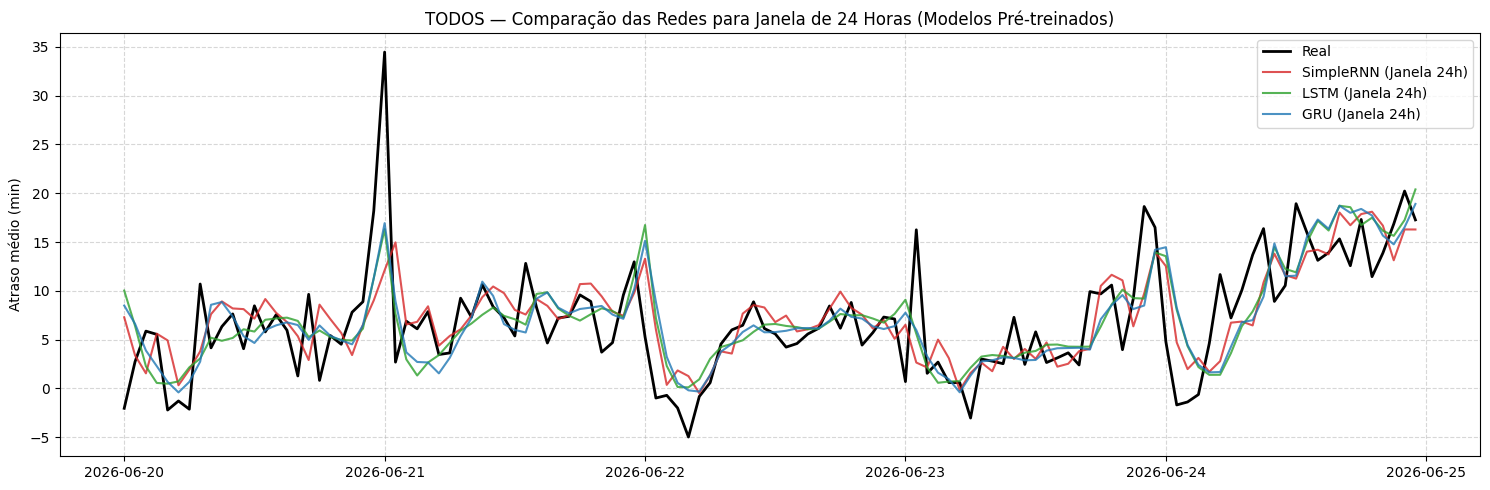

In [ ]:
# ---------------------------------------------------------------------------
# Geração de gráficos utilizando os modelos JÁ TREINADOS e armazenados na memória
# ---------------------------------------------------------------------------
janela_plot = slice(0, 24 * 5)  # Primeiros 5 dias do período de teste
cores = {"SimpleRNN": "tab:red", "LSTM": "tab:green", "GRU": "tab:blue"}

JANELAS_TESTAR_OPTUNA = [24]     # quantas horas passadas a rede enxerga

# Agrupando os dados de previsões detalhadas por janela no loop
for janela in JANELAS_TESTAR_OPTUNA:
    plt.figure(figsize=(15, 5))

    # Recria os conjuntos de tempo e o real correspondentes a esta janela específica
    _, _, tempo_local = criar_janelas_local(X_all, y_all, janela)
    te_local = tempo_local > fim_val
    idx_te_local = tempo_local[te_local]
    y_real_te_local = serie.loc[idx_te_local, ALVO].values

    # Plota a série real
    plt.plot(idx_te_local[janela_plot], y_real_te_local[janela_plot], label="Real", color="black", lw=2)

    # Filtra e plota as previsões desta janela para cada rede
    for tipo in ["SimpleRNN", "LSTM", "GRU"]:
        # Recupera diretamente o modelo já treinado que guardamos no dicionário
        modelo_local = modelos_treinados.get((janela, tipo))

        if modelo_local is not None:
            # Separamos os dados específicos desta janela para predição
            X_local, _, _ = criar_janelas_local(X_all, y_all, janela)
            X_te_local = X_local[te_local]

            # Realiza a predição diretamente, sem necessidade de re-treinamento
            prev_padronizada = modelo_local.predict(X_te_local, verbose=0).ravel()
            prev_minutos = scaler_y.inverse_transform(prev_padronizada.reshape(-1, 1)).ravel()

            plt.plot(idx_te_local[janela_plot], prev_minutos[janela_plot], label=f"{tipo} (Janela {janela}h)", color=cores[tipo], lw=1.5, alpha=0.8)
        else:
            print(f"Aviso: O modelo treinado para Janela {janela}h e tipo {tipo} não foi encontrado.")

    plt.ylabel("Atraso médio (min)")
    plt.title(f"{AEROPORTO} — Comparação das Redes para Janela de {janela} Horas (Modelos Pré-treinados)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"figuras/comparativo_janela_{janela}.png", dpi=150)
    plt.show()

In [ ]:
# Apresentação consolidada de todas as execuções
df_resultados = pd.DataFrame(resultados_multi_janelas)
display(df_resultados.sort_values(by="MAE Teste (min)"))

,Janela (horas),Modelo,MAE Teste (min),RMSE Teste (min)
2,24,GRU,3.047649,4.552289
1,24,LSTM,3.090240,4.650607
0,24,SimpleRNN,3.298559,4.802954


## Modelo de Referência (Baseline de Persistência)

Para validar se o aprendizado das redes recorrentes (SimpleRNN, LSTM, GRU) é realmente útil, implementamos o baseline de **Persistência (Naive)**. Este modelo assume que o atraso da próxima hora $t$ será exatamente igual ao atraso observado na hora anterior $t-1$:
$$\hat{y}_{t} = y_{t-1}$$


In [ ]:
# ---------------------------------------------------------------------------
# Cálculo do Baseline de Persistência (Previsão da hora t como sendo a hora t-1)
# ---------------------------------------------------------------------------

# Obter o índice e dados de teste correspondentes à janela de 24h
_, _, tempo_teste = criar_janelas_local(X_all, y_all, janela=24)
te_mask = tempo_teste > fim_val

# Valores reais do teste
y_real_teste = serie.loc[tempo_teste[te_mask], ALVO].values

# Para o baseline de persistência, a previsão para a hora 't' é o valor real de 't-1'
# Como os dados estão alinhados temporalmente, o valor real de t-1 é simplesmente a série deslocada
y_baseline_prev = serie.loc[tempo_teste[te_mask] - pd.Timedelta(hours=1), ALVO].values

# Calcular métricas para o Baseline
mae_baseline = np.mean(np.abs(y_real_teste - y_baseline_prev))
rmse_baseline = math.sqrt(mean_squared_error(y_real_teste, y_baseline_prev))

# Criar linha para o Baseline
linha_baseline = pd.DataFrame([{
    "Janela (horas)": 24,
    "Modelo": "Baseline (Persistência)",
    "MAE Teste (min)": mae_baseline,
    "RMSE Teste (min)": rmse_baseline
}])

# Concatenar na tabela global de resultados para comparação direta
df_resultados_com_baseline = pd.concat([df_resultados, linha_baseline], ignore_index=True)

print("Tabela Consolidada de Resultados (Ordenada por Menor MAE):")
display(df_resultados_com_baseline.sort_values(by="MAE Teste (min)").reset_index(drop=True))

Tabela Consolidada de Resultados (Ordenada por Menor MAE):


,Janela (horas),Modelo,MAE Teste (min),RMSE Teste (min)
0,24,GRU,3.047649,4.552289
1,24,LSTM,3.090240,4.650607
2,24,SimpleRNN,3.298559,4.802954
3,24,Baseline (Persistência),4.121478,6.269183


### Curvas de Aprendizado (Loss) para cada Janela e Modelo
O código abaixo realiza o treinamento das arquiteturas (SimpleRNN, LSTM, GRU) para cada uma das janelas (24h, 48h, 168h) e exibe as curvas de perda de treino e validação lado a lado em uma grade organizada.

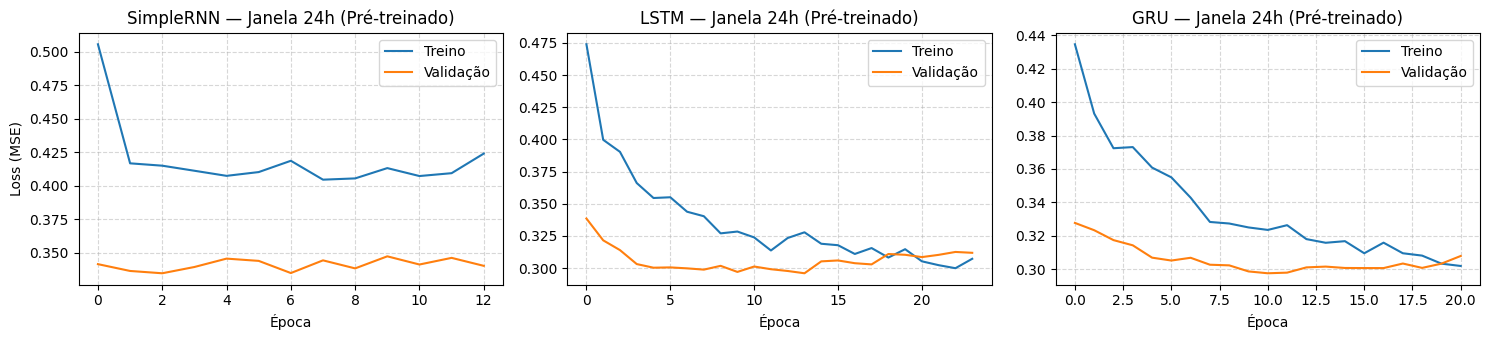

In [ ]:
# ---------------------------------------------------------------------------
# Geração das curvas de Loss utilizando o histórico de treino já salvo em memória
# ---------------------------------------------------------------------------
import matplotlib.pyplot as plt

JANELAS_TESTAR_OPTUNA = [24]     # quantas horas passadas a rede enxerga

# Usamos squeeze=False para garantir que axs sempre seja uma matriz 2D, mesmo se houver apenas 1 janela
fig, axs = plt.subplots(len(JANELAS_TESTAR_OPTUNA), 3, figsize=(15, 3.5 * len(JANELAS_TESTAR_OPTUNA)), sharey=False, squeeze=False)

for idx_j, janela in enumerate(JANELAS_TESTAR_OPTUNA):
    for idx_t, tipo in enumerate(["SimpleRNN", "LSTM", "GRU"]):
        # Recupera diretamente o histórico salvo
        historico = historicos_treinados.get((janela, tipo))

        ax = axs[idx_j, idx_t]
        if historico is not None:
            ax.plot(historico["loss"], label="Treino", color="tab:blue")
            ax.plot(historico["val_loss"], label="Validação", color="tab:orange")
            ax.set_title(f"{tipo} — Janela {janela}h (Pré-treinado)")
            ax.set_xlabel("Época")
            if idx_t == 0:
                ax.set_ylabel("Loss (MSE)")
            ax.legend()
            ax.grid(True, linestyle="--", alpha=0.5)
        else:
            ax.text(0.5, 0.5, f"Histórico não encontrado\n({tipo} - {janela}h)",
                    horizontalalignment='center', verticalalignment='center')

plt.tight_layout()
plt.savefig("figuras/curvas_aprendizado_multi_janelas.png", dpi=150)
plt.show()